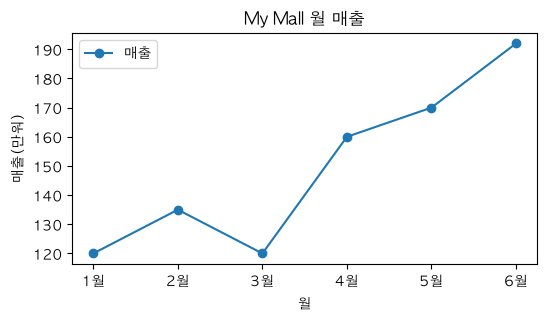

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns # 통계 그래프 라이브러리
import matplotlib.pyplot as plt

# 한글 폰트 설정
#plt.rcParams["font.family"] = "Malgun Gothic"   # Windows OS
plt.rcParams["font.family"] = "AppleGothic"     # 맥 OS

# Figure(캔버스), Axes(그래프)
fig, ax = plt.subplots(figsize=(6, 3))
# X축 데이터 (월)
months = ["1월", "2월", "3월", "4월", "5월", "6월"]
# Y축 데이터 (매출액, 만원)
sales = [120, 135, 120, 160, 170, 192]

# 선 그래프
ax.plot(months, sales, marker="o", label="매출")
ax.set_title("My Mall 월 매출")     # 그래프 제목
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()                         # 범례 표시
plt.show()                          # 차트 그리기

In [2]:
house = pd.read_csv('./datasets/usa_housing.csv')
print(house.shape)
house.describe()

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
count,300.000000,300.000000,300.000000,300.00000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,522761.916667,2.966667,2.464000,3052.75000,1962.616667,1.513333,1.062200,54324.770000,49.324033,5.096667
std,256922.348275,1.451175,0.886184,1194.97144,36.005431,1.116832,0.543896,24718.938552,28.833220,2.674165
min,112666.000000,1.000000,1.000000,840.00000,1902.000000,0.000000,0.110000,10163.000000,0.190000,1.000000
25%,299936.500000,2.000000,1.700000,2053.50000,1931.750000,1.000000,0.570000,34175.000000,22.547500,3.000000
50%,505806.500000,3.000000,2.400000,3127.00000,1961.000000,1.000000,1.085000,54896.500000,49.970000,5.000000
75%,744603.750000,4.000000,3.200000,4081.00000,1994.000000,3.000000,1.482500,74108.000000,74.402500,8.000000
max,999684.000000,5.000000,4.000000,4997.00000,2022.000000,3.000000,2.000000,99881.000000,99.710000,9.000000


In [3]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape
small

,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
9,737147,3,2.6,4191,2017,0,1.65,66549,37.60,3
33,586232,4,1.3,3854,2021,2,1.39,30103,26.93,2
112,616588,2,1.2,3872,2016,0,0.17,61112,20.98,8
119,979858,5,3.8,4307,2020,0,0.38,41822,37.14,4
189,161087,5,2.4,964,2021,1,0.24,34022,12.80,3
191,175766,2,2.1,1743,2019,3,1.37,70428,39.34,3
205,237337,3,1.6,2355,2022,3,1.55,32420,2.20,6
218,364712,3,1.3,3373,2019,0,0.77,29877,22.61,9
230,502690,2,2.8,3457,2022,3,0.89,52080,11.19,8
251,515515,2,1.5,3481,2022,1,0.50,73530,34.37,7


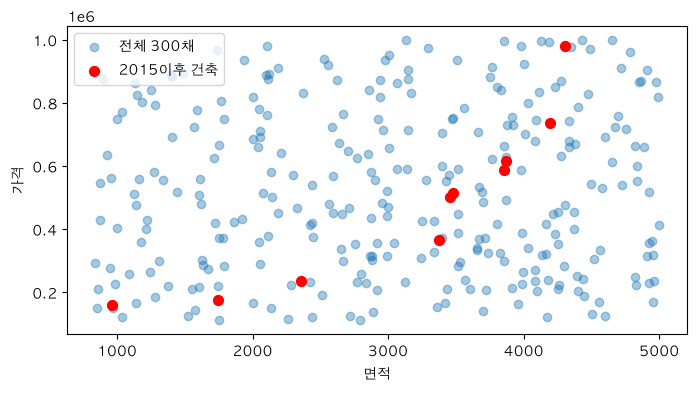

전체 300채의 상관계수: 0.08
10채의 상관계수: 0.89


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.scatter(house['SquareFeet'], house['Price'], alpha=0.4, label="전체 300채")
plt.scatter(small["SquareFeet"], small['Price'], color="red", s=50, label="2015이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()


print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]),2))
print("10채의 상관계수:", round(small["SquareFeet"].corr(small["Price"]),2))

In [5]:
# 시드(seed) : 난수 발생시 참고하는 데이터, 동일한 seed 값을 적용하는 
# 항상 동일한 난수가 발생
rng = np.random.default_rng(40)

n = 200
area = rng.uniform(20, 85, n) # 20 이상 85 미만에서 균등하게 n개 만큼 난수 발생

# 선형회귀
# y = wx + b
# w: 기울기 450
# b: 절편(편향) 5000
price = (area * 450 + 5000 + rng.normal(0, 2500, n)).round(-1)

# 특이 매물 5건 생성
special = rng.choice(n, 5, replace=False) # replace = False 같은 번호를 중복해서 뽑지 않는다.
price[special] += rng.uniform(15000, 25000, 5).round(-1)

office = pd.DataFrame({'area':area, "price": price})
office.describe().round(1)


,area,price
count,200.0,200.0
mean,52.8,29138.4
std,18.6,9112.1
min,22.0,11400.0
25%,37.4,21615.0
50%,52.0,28965.0
75%,67.4,36377.5
max,84.9,58460.0


In [6]:
# 파일 저장
office.to_csv("./datasets/office.csv", index=False)

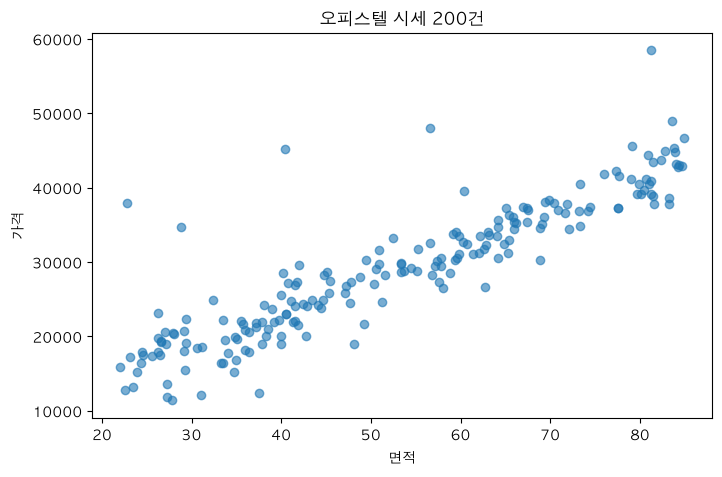

상관계수 :  0.896


In [7]:
# 산점도 차트

# 캔버스(Figure) 생성
plt.figure(figsize=(8,5))
# 산점도 차트
plt.scatter(office['area'], office["price"], alpha=0.6) # 알파는 점의 투명도
# 타이틀과 x, y 레이블
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수 : ", (office["area"].corr(office["price"])).round(3))


In [8]:
from sklearn.linear_model import LinearRegression

X = office[["area"]]
y = office["price"]

# 선형 회귀 모델 만들기
model = LinearRegression()
# 학습 : X(입력값), y(정답)
model.fit(X, y)

print(f"기울기 w = {model.coef_[0].round(2)} 정답: 450")
print(f"절편 b = {model.intercept_.round(2)} 정답: 5000")

기울기 w = 439.46 정답: 450
절편 b = 5926.68 정답: 5000


In [9]:
# 33, 59 가격 예측
new = pd.DataFrame({"area":[33, 59]})
model.predict(new).round(-1)

array([20430., 31850.])

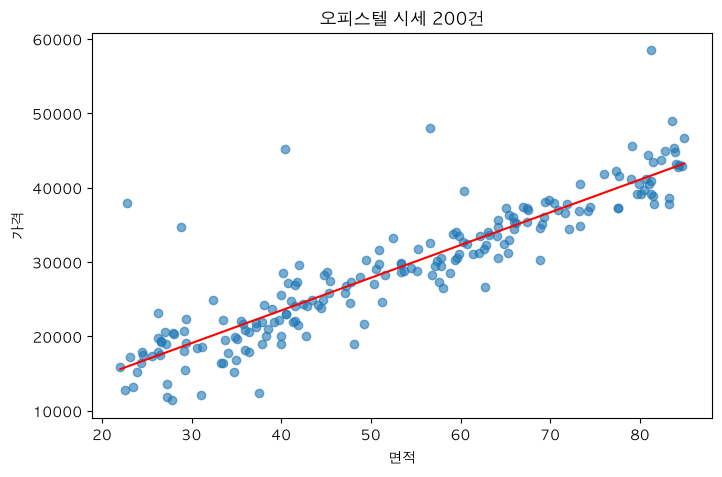

In [10]:
# 학습한 모델로 예측하기
y_pred = model.predict(X)

line = X.sort_values("area")
line_pred = model.predict(line)

# 캔버스(Figure) 생성
plt.figure(figsize=(8,5))
# 산점도 차트
plt.scatter(office['area'], office["price"], alpha=0.6, label="실제 시세") # 알파는 점의 투명도
# 모델의 직선
plt.plot(line["area"], line_pred, color="red", label="모델의 직선")


# 타이틀과 x, y 레이블
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

In [11]:
# MAE, MSE, RMSE
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
# MAE: 오차 절댓값의 평균 => 평균적으로 얼마만큼 틀리나?
print(f"MAE = {mean_absolute_error(y,y_pred):,.0f}")
# MSE: 오차 제곱의 평균 (단위 제곱)
print(f"MSE = {mean_squared_error(y,y_pred):,.0f}")
# RMSE: 오차 제곱 평균의 루트 (원래 단위)
print(f"RMSE = {root_mean_squared_error(y,y_pred):,.0f}")
# R SCORE: 0 ~ 1
print(f"R_SCORE={r2_score(y, y_pred):,.3f}")


MAE = 2,493
MSE = 16,240,971
RMSE = 4,030
R_SCORE=0.803


In [12]:
normal = np.ones(len(office),dtype=bool)
normal[special] = False
print("특이매물", special)
print("정상매물", normal.sum())

특이매물 [53 13  2 92 71]
정상매물 195


In [13]:
all_rows = np.ones(len(office), dtype=bool)
cases = [("전체 200건", all_rows), ("특이매물 제외한 195", normal)]

for name, mask in cases:
    y_true = y[mask]        # 실제가격
    y_hat = y_pred[mask]    # 예측가격

# MAE : 오차 절댓값의 평균
mae = mean_absolute_error(y_true, y_hat)
# RMSE
rmse = root_mean_squared_error(y_true, y_hat)
# R2
r2 = r2_score(y_true, y_hat)
print(f"{name} MAE {mae} | RMSE {rmse} | RScore {r2}")

특이매물 제외한 195 MAE 2075.103976845269 | RMSE 2731.535391445735 | RScore 0.9023854405903358
